In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np

In [ ]:
data=pd.read_csv('/content/Student_Marks.csv')
data

,number_courses,time_study,Marks
0,3,4.508,19.202
1,4,0.096,7.734
2,4,3.133,13.811
3,6,7.909,53.018
4,8,7.811,55.299
...,...,...,...
95,6,3.561,19.128
96,3,0.301,5.609
97,4,7.163,41.444
98,7,0.309,12.027


In [ ]:
data.head()

,number_courses,time_study,Marks
0,3,4.508,19.202
1,4,0.096,7.734
2,4,3.133,13.811
3,6,7.909,53.018
4,8,7.811,55.299


In [ ]:
data.tail()

,number_courses,time_study,Marks
95,6,3.561,19.128
96,3,0.301,5.609
97,4,7.163,41.444
98,7,0.309,12.027
99,3,6.335,32.357


In [ ]:
data.describe()

,number_courses,time_study,Marks
count,100.000000,100.000000,100.000000
mean,5.290000,4.077140,24.417690
std,1.799523,2.372914,14.326199
min,3.000000,0.096000,5.609000
25%,4.000000,2.058500,12.633000
50%,5.000000,4.022000,20.059500
75%,7.000000,6.179250,36.676250
max,8.000000,7.957000,55.299000


In [ ]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100 entries, 0 to 99
Data columns (total 3 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   number_courses  100 non-null    int64  
 1   time_study      100 non-null    float64
 2   Marks           100 non-null    float64
dtypes: float64(2), int64(1)
memory usage: 2.5 KB


In [ ]:
data.head()

,number_courses,time_study,Marks
0,3,4.508,19.202
1,4,0.096,7.734
2,4,3.133,13.811
3,6,7.909,53.018
4,8,7.811,55.299


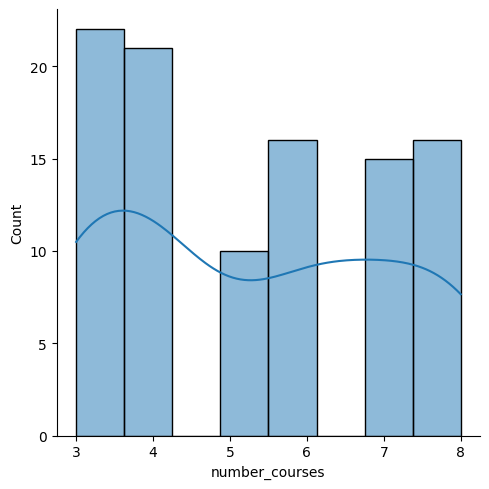

In [ ]:
sns.displot(x=data.number_courses,kde=True)

<Axes: xlabel='time_study', ylabel='Count'>

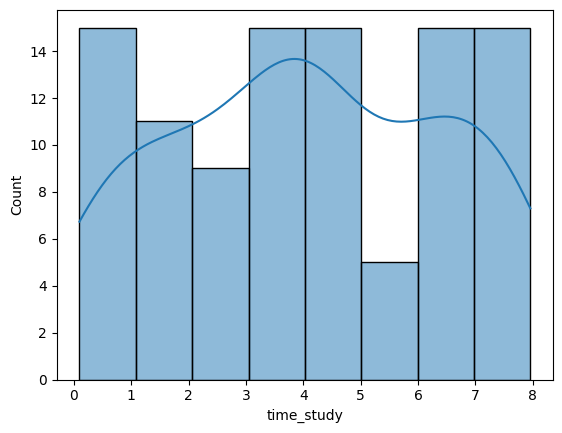

In [ ]:
sns.histplot(x=data.time_study,kde=True)

<Axes: xlabel='Marks', ylabel='Count'>

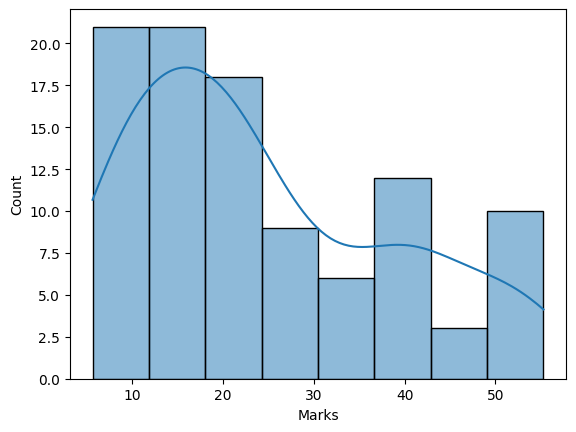

In [ ]:
sns.histplot(x=data.Marks,kde=True)

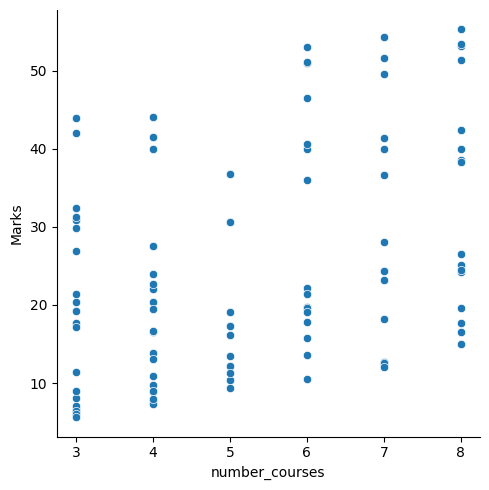

In [ ]:
sns.relplot(x='number_courses',y='Marks',data=data)

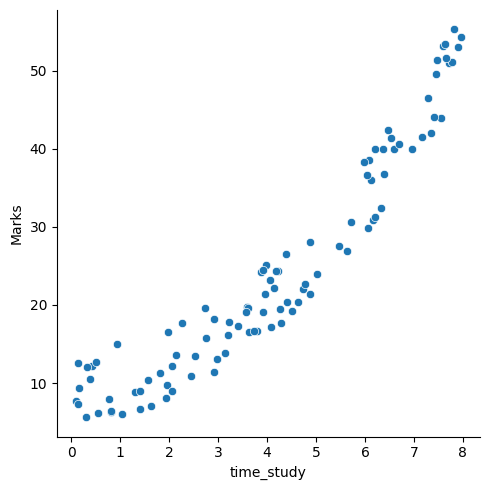

In [ ]:
sns.relplot(x='time_study',y='Marks',data=data)

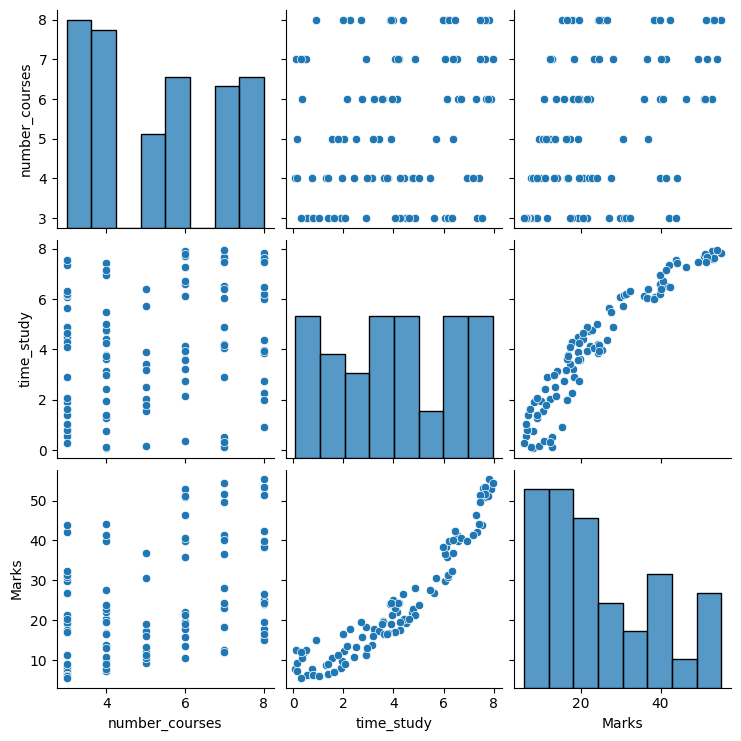

In [ ]:
sns.pairplot(data)

<Axes: xlabel='number_courses'>

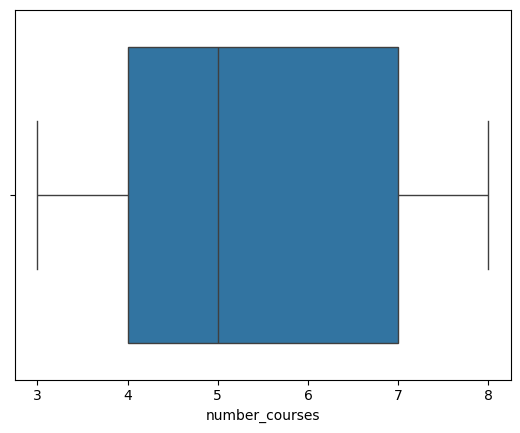

In [ ]:
sns.boxplot(x='number_courses',data=data)

<Axes: xlabel='time_study'>

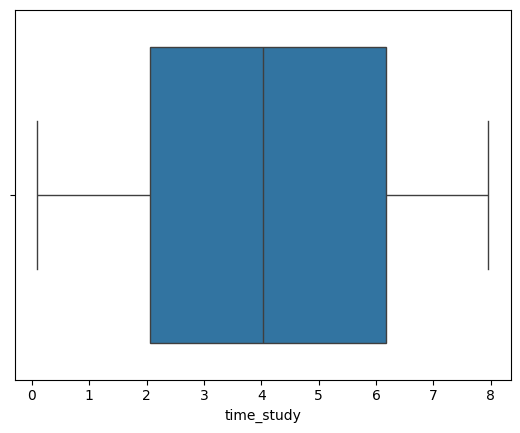

In [ ]:
sns.boxplot(x='time_study',data=data)

In [ ]:
x=data.corr(numeric_only=True)

<Axes: >

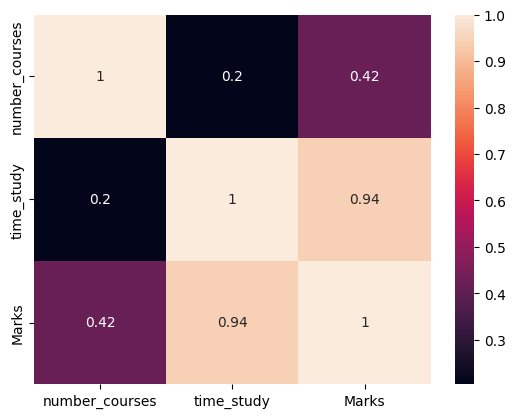

In [ ]:
sns.heatmap(x,annot=True)

In [ ]:
x=data[['number_courses','time_study']]
y=data.Marks

In [ ]:
x

,number_courses,time_study
0,3,4.508
1,4,0.096
2,4,3.133
3,6,7.909
4,8,7.811
...,...,...
95,6,3.561
96,3,0.301
97,4,7.163
98,7,0.309


In [ ]:
y

,Marks
0,19.202
1,7.734
2,13.811
3,53.018
4,55.299
...,...
95,19.128
96,5.609
97,41.444
98,12.027


In [ ]:
from sklearn.model_selection import train_test_split
x_train,x_test,y_train,y_test=train_test_split(x,y,test_size=0.2,random_state=40)

In [ ]:
x_train

,number_courses,time_study
72,3,4.633
66,4,5.473
69,6,3.948
67,3,0.550
26,7,0.508
...,...,...
56,8,7.641
37,6,7.283
7,5,3.413
91,8,2.730


In [ ]:
y_train

,Marks
72,20.398
66,27.569
69,21.400
67,6.185
26,12.647
...,...
56,53.359
37,46.453
7,17.264
91,19.564


In [ ]:
from sklearn.linear_model import LinearRegression
LR=LinearRegression()
LR.fit(x_train,y_train)

LinearRegression()

In [ ]:
y_pred=LR.predict(x_test)

In [ ]:
y_test

,Marks
79,6.349
75,6.217
63,21.379
15,19.466
38,41.358
11,12.132
40,7.336
45,8.924
39,51.142
62,19.590


In [ ]:
y_pred

array([ 2.20921716,  2.19835534, 24.28042058, 22.88660702, 40.9718824 ,
        7.78904458,  0.51127284,  9.03043554, 45.80345968, 23.16201109,
       27.57926733, 49.82618913, 25.70524742, 31.18188762, 19.69008977,
       40.42529023, 39.99396204, 39.38955928, 31.36232247, 27.0521122 ])

In [ ]:
from sklearn.metrics import mean_squared_error,mean_absolute_error

In [ ]:
print(mean_squared_error(y_test,y_pred))

13.772188001122222


In [ ]:
print(mean_absolute_error(y_test,y_pred))

3.2422874410099496


In [ ]:
### user value prediction
courses_m=int(input("enter number of courses:"))
study_m=int(input("enter study hours:"))

pred=LR.predict([[courses_m,study_m]])
print("THE PREDICTED MARKS IS",pred)

enter number of courses:10
enter study hours:15
THE PREDICTED MARKS IS [92.69619173]


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LinearRegression was fitted with feature names
  warnings.warn(


In [ ]:
import pickle

with open("marks.pkl","wb") as f:
  pickle.dump(LR,f)